In [ ]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#In this code we will implement our environments: race and chase
#Jeremy Kedziora
#18 September 2024
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@


In [1]:
#@@@@@@@@@@@@@@@@@@@@@@@
#import useful libraries
#@@@@@@@@@@@@@@@@@@@@@@@
import numpy as np
import itertools

import copy

import seaborn as sb

from tqdm import tqdm
from IPython.display import clear_output
import time
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#two classes for these two environments
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class race_environment:
    '''A class to manage the race'''
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.track = np.zeros((config['track_shape']['height']
                  ,config['track_shape']['width']))    #set up an array to represent the track
        self.track[config['track_shape']['v_track_width']:,config['track_shape']['h_track_width']:] = 1    #block the no-go area
        self.state = {}
        if not config['starting_position']:
            self.state['position'] = {'X':np.random.choice(a = range(config['track_shape']['v_track_width']))
                                      ,'Y':config['track_shape']['height']-1}
        else:
            self.state['position'] = copy.deepcopy(config['starting_position'])
        if not config['starting_velocity']:
            self.state['V'] = {'V':0,'H':0}
        else:
            self.state['V'] = copy.deepcopy(config['starting_velocity'])    #set up the state -- here it will be position and velocity
        self.old_position = copy.deepcopy(self.state['position'])
        self.config = config        
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reset(self):
        '''A function to reset to initial conditions'''
        self.state = {'position':{'X':np.random.choice(a = range(self.config['track_shape']['v_track_width']))
                                      ,'Y':self.config['track_shape']['height']-1}
                      ,'V':{'V':0,'H':0}}    #set up the state -- here it will be position and velocity
        self.old_position = copy.deepcopy(self.state['position'])

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def update_V(self,a):
        '''A function to update vert and horiz velocity
            Takes -- a, a dictionary containing the vert and horiz acceleration
        '''
        self.state['V']['V'] = min(5,max(0,self.state['V']['V'] + a['V']))    #update the vert velocity
        self.state['V']['H'] = min(5,self.state['V']['H'] + a['H'])    #update the horiz velocity

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def update_Position(self):
        '''A function to update vert and horiz position
        '''        
        self.state['position']['X'] = self.state['position']['X'] + self.state['V']['H']    #update the horiz position
        self.state['position']['Y'] = self.state['position']['Y'] - self.state['V']['V']    #update the vert position

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def obstacle_check(self):
        '''A function to check if the player crosses an obstacle'''
        crash = False
        if self.state['position']['X'] != self.old_position['X']:
            m = (self.state['position']['Y'] - self.old_position['Y'])/(self.state['position']['X'] - self.old_position['X'])
            b = self.state['position']['Y'] - m*self.state['position']['X']
            xs = np.linspace(start = self.old_position['X']
                        ,stop = self.state['position']['X']
                        ,num = 2*abs(self.state['position']['X'] - self.old_position['X']) + 1)
            ys = np.round(m*xs + b)
            xs = np.round(xs)
            for x,y in zip(xs,ys):

                if self.track[int(y),int(x)] == 1:
                    crash = True
                    break
        else:
            if self.track[self.state['position']['Y'],self.state['position']['X']] == 1:    #and if the agent is in the no-go
                crash = True    #set crash to true
        return crash

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def check_crash(self):
        '''A function to check if the agent crashed'''
        crash = False
        if self.state['position']['X'] < 0:    #if the agent goes out of bounds to the left
            crash = True    #set crash to true
        if self.state['position']['Y'] < 0:    #if the agent goes out of bounds to the top
            crash = True    #set crash to true
        if self.state['position']['X'] >= 0 and self.state['position']['X'] < self.config['track_shape']['width']-1 and self.state['position']['Y'] >= 0:    #if the agent is within the array
            crash = self.obstacle_check()
        return crash

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def check_win(self):
        '''A function to check if the agent won'''
        win = False    #assume no win
        if self.state['position']['X'] >= self.config['track_shape']['width'] and self.state['position']['Y'] < self.config['track_shape']['h_track_width']:    #if the agent is over the finish line
            win = True    #set win to true
        return win

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reward(self,sp):
        return 1/max(1,((sp['X'] - (self.config['track_shape']['width'] - 1))**2
                          + (self.config['track_shape']['h_track_width']/2.0 - sp['Y'])**2))
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def step(self,a):
        '''A function to evolve the environment
            Takes -- a, a dictionary containing the vert and horiz acceleration
        '''
        outcome = ''    #track crash/win
        done = False    #set the done indicator
        self.update_V(a)    #update the velocity
        self.update_Position()    #update the position
        crash = self.check_crash()    #check if the agent crashed
        self.old_position = copy.deepcopy(self.state['position'])
        r = self.reward(self.state['position'])
        if crash:
            outcome = 'crash'
            r = r * -1
            self.reset()
        if not crash:    #if the agent didn't crash...
            win = self.check_win()    #check if the agent won
            if win:
                outcome = 'won'
                done = True
                r = 10
        return {'state':self.state
                     ,'reward':r
                     ,'done':done
                    ,'Win/Lost':outcome}


In [3]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#two classes for these two environments
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class Agent:
    '''A class to manage the agent'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.Z = {} # state action pairs
        self.Q = {} # blank Q-values
        self.config = config

    def setup_Q(self, track_shape):
        # creates all state action pairs, and sets to zero for Q values and Z
        for x in range(0, track_shape['width']):
            for y in range(0, track_shape['height']):
                s = f"{y}_{x}"
                self.Q[s] = {}
                self.Z[s] = {}
                for a1, a2 in self.config['A']:
                    a = f"{a1}_{a2}"
                    self.Q[s][a] = 0
                    self.Z[s][a] = []

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def update_Q(self,state, action, value):
        self.Q[state][action] = value
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def pi(self,state,epsilon):
        actions = self.Q[state] # get q-values for each action
        max_act = max(actions, key=actions.get)
        if self.Q[state][max_act] >= epsilon:
            v, h = max_act.split('_')
            action = {
                'V':int(v),
                'H':int(h)
            }
        else:
            act = np.random.choice(list(actions.keys()))
            v, h = act.split('_')
            action = {
                'V':int(v),
                'H':int(h)
            }
        return action

In [4]:
def to_state(state):
    # {'position': {'X': np.int64(3), 'Y': 29}, 'V': {'V': 0, 'H': 0}} to string
    x = state['position']['X']
    y = state['position']['Y']
    return f"{y}_{x}"

In [5]:
#@@@@@@@@@@@@@@@@@@@@@@@
#Set up the environments
#@@@@@@@@@@@@@@@@@@@@@@@
height = 30    #set track height
width = 25    #set track width
v_track_width = 10    #set road width for the vert section
h_track_width = 10    #set road width for the horiz section
env_config = {'track_shape':{'height':height
                              ,'width':width
                              ,'v_track_width':v_track_width
                              ,'h_track_width':h_track_width}
          ,'starting_position':None
         ,'starting_velocity':None}    #set up the config for the environment

agent_config = {'epsilon':0.1,'gamma':0.9,'A':list(itertools.product([-1,0,1],[-1,0,1]))}    #set up the config for the agent

renv = race_environment(env_config)    #set up the environment


In [6]:
###########################
# 100 simulated runs
# no policy for selecting actions
###########################
renv = race_environment(env_config) 
races= {}

random_data={
    'episode':[],
    'T':[],
    'num_crash':[],
    'ep_reward':[]
}

for i in tqdm(range(100)):
    races[i]= {}
    done = False
    t = 0
    c = 0
    avg_r = 0
    action = {
        'V':1,
        'H':1
    }
    while not done:
        rewards = renv.step(action)
        t+=1
        action['V'] = np.random.choice([-1,0,1])
        action['H'] = np.random.choice([-1,0,1])
        done = rewards['done']
        avg_r += rewards['reward']
        if rewards['Win/Lost'] == 'crash':
            c+=1
        # clear_output(wait=True)
        # print(i, t, rewards)
    random_data['episode'].append(i)
    random_data['T'].append(t)
    random_data['num_crash'].append(c)
    random_data['ep_reward'].append(avg_r)
    renv.reset()

random_df = pd.DataFrame(data=random_data)
print(random_df['T'].mean())
random_df.head()

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:25<00:00,  3.97it/s]

2998.95


,episode,T,num_crash,ep_reward
0,0,2396,365,12.455244
1,1,335,43,11.145623
2,2,4676,667,14.873835
3,3,661,92,10.929371
4,4,5729,890,15.684077


In [43]:
random_df['num_crash'].mean()

447.83

<AxesSubplot:xlabel='episode', ylabel='T'>

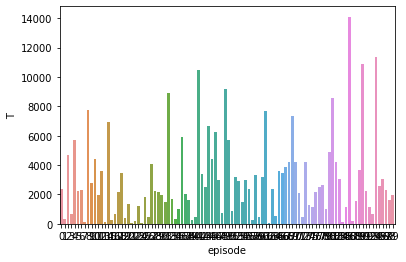

In [7]:
sns.barplot(data=random_df, x='episode', y='T')

<AxesSubplot:xlabel='episode', ylabel='ep_reward'>

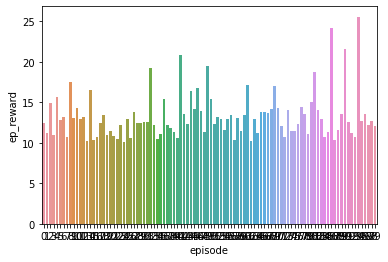

In [8]:
sns.barplot(data=random_df, x='episode', y='ep_reward')

<AxesSubplot:xlabel='episode', ylabel='num_crash'>

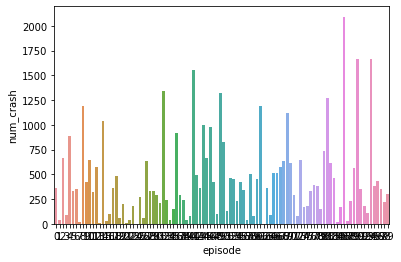

In [9]:
sns.barplot(data=random_df, x='episode', y='num_crash')

In [59]:
# random_df

len(random_df[random_df['num_crash']<=10])

3

In [10]:
random_df.to_csv('random_pi.csv', index=False)

In [7]:
# Monte Carlo
agent_config = {'epsilon':0.4,'gamma':0.5,'A':list(itertools.product([-1,0,1],[-1,0,1]))}

renv = race_environment(env_config)

agent = Agent(agent_config)
agent.setup_Q(env_config['track_shape'])

epsilon = agent_config['epsilon']
gamma = agent_config['gamma']

# N = 1000 # number episodes
N = 1000

state = to_state(renv.state)
action = agent.pi(state, epsilon)

s_a_sequence = [""+state+f"={action['V']}_{action['H']}"]
r_sequence = [None]

runtime_data={
    'episode':[],
    'T':[],
    'num_crash':[],
    'ep_reward':[]
}

for n in range(N):
    T = 0
    done = False
    c = 0
    avg_r = 0
    while not done:
        # sample actions according to pi
        rewards = renv.step(action)
        r = rewards['reward'] 
        if not rewards['done']:
            state = to_state(rewards['state'])
            action = agent.pi(state, epsilon)
            s_a_sequence.append(f"{state}={action['V']}_{action['H']}")
            
        else:
            s_a_sequence.append(f"{state}={0}_{0}")
        avg_r += rewards['reward']
        if rewards['Win/Lost'] == 'crash':
            c+=1
        r_sequence.append(r)
        T+=1
        done = rewards['done']
        # clear_output(wait=True)
        print(n, T, rewards)
        
    G = 0
    for t in list(range(T))[::-1]: # iteate backwards over timepoints
        s_t, a_t  = s_a_sequence[t].split('=')
        G = r_sequence[t+1] + (gamma*G)
        if not (s_a_sequence[t] in s_a_sequence[0:t]): # only first_visit
            agent.Z[s_t][a_t].append(G)
            agent.update_Q(s_t,a_t, np.mean(agent.Z[s_t][a_t]))
    runtime_data['episode'].append(n)
    runtime_data['T'].append(T)
    runtime_data['num_crash'].append(c)
    runtime_data['ep_reward'].append(avg_r)
    renv.reset()

monte_data = pd.DataFrame(data=runtime_data)
monte_data.to_csv('monte_carlo.csv', index=False)

10 767 {'state': {'position': {'X': 26, 'Y': 3}, 'V': {'V': 0, 'H': 4}}, 'reward': 10, 'done': True, 'Win/Lost': 'won'}


ValueError: not enough values to unpack (expected 2, got 1)

In [23]:
monte_df = pd.read_csv('monte_carlo.csv')
monte_df.head()

,episode,T,num_crash,ep_reward
0,0,27170,4157,39.913438
1,1,788,123,10.958956
2,2,5277,836,15.774304
3,3,7263,1125,18.494403
4,4,4020,616,15.059519


<AxesSubplot:xlabel='T', ylabel='Count'>

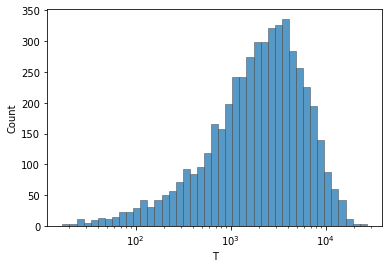

In [24]:
sns.histplot(
    monte_df,
    x="T", 
    multiple="stack",
    palette="light:m_r",
    edgecolor=".3",
    linewidth=.5,
    log_scale=True,
)

<AxesSubplot:xlabel='episode', ylabel='T'>

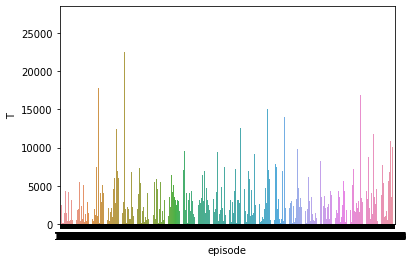

In [25]:
sns.barplot(data=monte_df, x='episode', y='T')

<AxesSubplot:xlabel='episode', ylabel='ep_reward'>

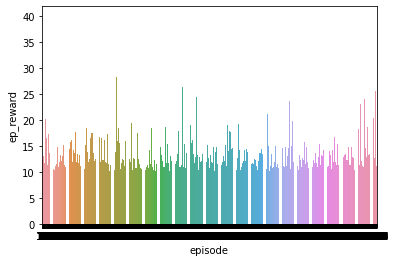

In [26]:
sns.barplot(data=monte_df, x='episode', y='ep_reward')

<AxesSubplot:xlabel='episode', ylabel='num_crash'>

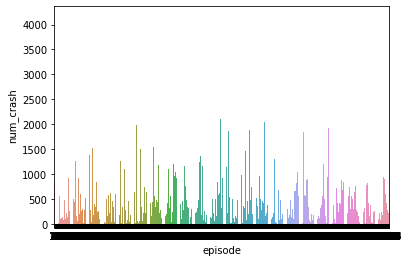

In [27]:
sns.barplot(data=monte_df, x='episode', y='num_crash')

In [29]:
monte_df['T'].mean(), monte_df['num_crash'].mean()

(3110.157, 477.6384)

In [60]:
len(monte_df[monte_df['num_crash']<=10])

104

In [62]:
monte_df.sort_values(by=['T']).head()

,episode,T,num_crash,ep_reward
1010,1010,17,0,10.165647
3132,3132,19,1,10.178443
1127,1127,19,0,10.616575
1945,1945,20,0,10.164786
632,632,21,0,10.160624


In [65]:
monte_df.sort_values(by=['num_crash']).head()

,episode,T,num_crash,ep_reward
1010,1010,17,0,10.165647
1127,1127,19,0,10.616575
632,632,21,0,10.160624
1945,1945,20,0,10.164786
2544,2544,25,1,10.258027


In [ ]:
# SARSA w/ Greedy

renv = race_environment(env_config)
agent_config = {'epsilon':0.4,'gamma':0.5,'A':list(itertools.product([-1,0,1],[-1,0,1]))}
agent = Agent(agent_config)
agent.setup_Q(env_config['track_shape'])

epsilon = agent_config['epsilon']
gamma = agent_config['gamma']
alpha = 0.7

# N = 1000 # number episodes
N = 100

state = to_state(renv.state)
action = agent.pi(state, epsilon)


runtime_sarsa={
    'episode':[],
    'T':[],
    'num_crash':[],
    'ep_reward':[]
}

for n in range(N):
    T = 0
    done = False
    avg_r = 0
    c = 0
    while not done:
        a_c = f"{action['V']}_{action['H']}"
        # sample actions according to pi
        rewards = renv.step(action) # implement action to generate r'
        r = rewards['reward']
        if not rewards['done']:
            new_state = to_state(rewards['state'])
            new_action = agent.pi(state, epsilon) # sample a' according to pi(s')
            a_n = f"{new_action['V']}_{new_action['H']}" 
            
            # update Q values
            new_Q = agent.Q[state][a_c] + alpha*(r + gamma*agent.Q[new_state][a_n] - agent.Q[state][a_c])
            agent.update_Q(state,a_c, new_Q)
            action = new_action
            state = new_state
            
        avg_r += rewards['reward']
        if rewards['Win/Lost'] == 'crash':
            c+=1
        
        T+=1   
        done = rewards['done']
        
        # clear_output(wait=True)
        print(n, T, rewards)
        
    runtime_sarsa['episode'].append(n)
    runtime_sarsa['T'].append(T)
    runtime_sarsa['num_crash'].append(c)
    runtime_sarsa['ep_reward'].append(avg_r)
    renv.reset()

sarsa_data = pd.DataFrame(data=runtime_sarsa)
sarsa_data.to_csv('sarsa.csv', index=False)

4 94 {'state': {'position': {'X': 4, 'Y': 29}, 'V': {'V': 0, 'H': 1}}, 'reward': 0.0010245901639344263, 'done': False, 'Win/Lost': ''}


In [30]:
sarsa_df = pd.read_csv('sarsa.csv')
sarsa_df.head()

,episode,T,num_crash,ep_reward
0,0,97,10,10.428122
1,1,4571,693,15.094724
2,2,7003,1077,17.904029
3,3,3842,596,14.188115
4,4,10300,1568,21.293417


<AxesSubplot:xlabel='T', ylabel='Count'>

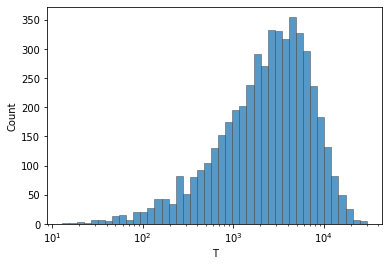

In [31]:
sns.histplot(
    sarsa_df,
    x="T", 
    multiple="stack",
    palette="light:m_r",
    edgecolor=".3",
    linewidth=.5,
    log_scale=True,
)

<AxesSubplot:xlabel='episode', ylabel='T'>

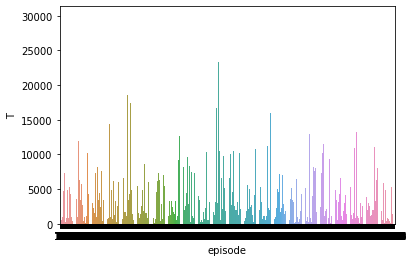

In [37]:
sns.barplot(data=sarsa_df, x='episode', y='T')

<AxesSubplot:xlabel='episode', ylabel='ep_reward'>

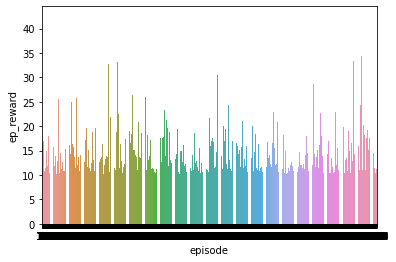

In [38]:
sns.barplot(data=sarsa_df, x='episode', y='ep_reward')

<AxesSubplot:xlabel='episode', ylabel='num_crash'>

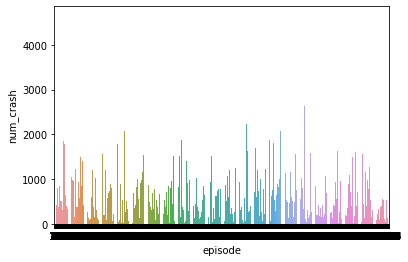

In [39]:
sns.barplot(data=sarsa_df, x='episode', y='num_crash')

In [32]:
sarsa_df['T'].mean(), sarsa_df['num_crash'].mean()

(3702.4068, 568.222)

In [48]:
sarsa_df.loc[sarsa_df['episode']>4000]['num_crash'].mean(), sarsa_df.loc[sarsa_df['episode']<1000]['num_crash'].mean()

(563.6546546546547, 580.622)

In [49]:
sarsa_df.loc[sarsa_df['episode']>4000]['T'].mean(), sarsa_df.loc[sarsa_df['episode']<1000]['T'].mean()

(3672.4474474474473, 3783.269)

In [66]:
sarsa_df.sort_values(by=['num_crash'])

,episode,T,num_crash,ep_reward
603,603,13,0,10.131371
3570,3570,20,0,10.315684
2948,2948,19,0,10.280257
4360,4360,21,0,10.183454
3641,3641,15,0,10.326771
...,...,...,...,...
1264,1264,25211,3896,37.996768
166,166,25346,3906,37.647039
1988,1988,27485,4224,39.918934
4937,4937,28242,4360,41.690513


In [58]:
len(sarsa_df[sarsa_df['num_crash']<=10])

75

In [ ]:
# Expected SARSA w/Epsilon Greedy
agent_config = {'epsilon':0.3,'gamma':0.7,'A':list(itertools.product([-1,0,1],[-1,0,1]))}

renv = race_environment(env_config)

agent = Agent(agent_config)
agent.setup_Q(env_config['track_shape'])

epsilon = agent_config['epsilon']
gamma = agent_config['gamma']
alpha = 0.7

# N = 1000 # number episodes
N = 1000

state = to_state(renv.state)
action = agent.pi(state, epsilon)

runtime_esarsa={
    'episode':[],
    'T':[],
    'num_crash':[],
    'ep_reward':[]
}

for n in range(N):
    T = 0
    done = False
    avg_r = 0
    c = 0
    while not done:
        a_c = f"{action['V']}_{action['H']}"
        # sample actions according to pi
        rewards = renv.step(action) # implement action to generate r'
        r = rewards['reward']
        if not rewards['done']:
            new_state = to_state(rewards['state'])
            new_action = agent.pi(state, epsilon) # sample a' according to pi(s')
            a_n = f"{new_action['V']}_{new_action['H']}"

            # update Q values
            new_Q = agent.Q[state][a_c] + alpha*(r + gamma * sum(agent.Q[state].values())*agent.Q[new_state][a_n] - agent.Q[state][a_c])
            
            
            agent.update_Q(state,a_c, new_Q)
            action = new_action
            state = new_state
            
        avg_r += rewards['reward']
        if rewards['Win/Lost'] == 'crash':
            c+=1
        T+=1   
        done = rewards['done']
        
        # clear_output(wait=True)
        print(n, T, rewards)
        
    runtime_esarsa['episode'].append(n)
    runtime_esarsa['T'].append(T)
    runtime_esarsa['num_crash'].append(c)
    runtime_esarsa['ep_reward'].append(avg_r)
    renv.reset()

esarsa_data = pd.DataFrame(data=runtime_sarsa)
esarsa_data.to_csv('expected_sarsa.csv', index=False)

In [33]:
esarsa_data = pd.read_csv('expected_sarsa.csv')
esarsa_data.head()

,episode,T,num_crash,ep_reward
0,0,7455,1136,18.304546
1,1,1142,189,11.264097
2,2,4057,623,14.487817
3,3,7894,1229,18.581465
4,4,4738,698,16.017081


<AxesSubplot:xlabel='T', ylabel='Count'>

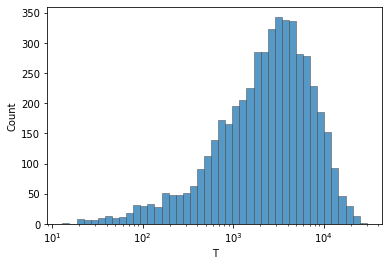

In [34]:
sns.histplot(
    esarsa_data,
    x="T", 
    multiple="stack",
    palette="light:m_r",
    edgecolor=".3",
    linewidth=.5,
    log_scale=True,
)

<AxesSubplot:xlabel='episode', ylabel='T'>

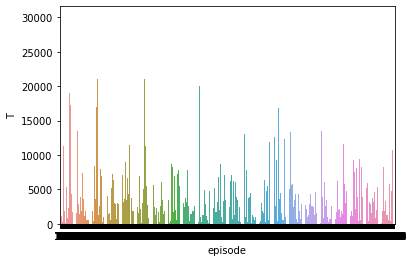

In [40]:
sns.barplot(data=esarsa_data, x='episode', y='T')

<AxesSubplot:xlabel='episode', ylabel='ep_reward'>

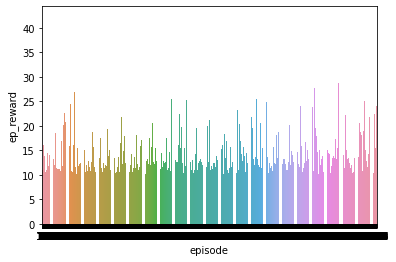

In [41]:
sns.barplot(data=esarsa_data, x='episode', y='ep_reward')

<AxesSubplot:xlabel='episode', ylabel='num_crash'>

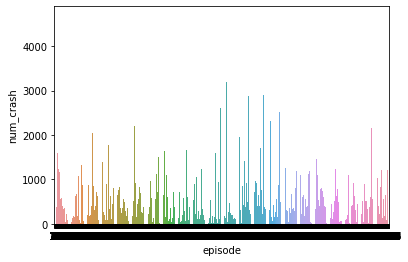

In [42]:
sns.barplot(data=esarsa_data, x='episode', y='num_crash')

In [36]:
esarsa_data['T'].mean(), esarsa_data['num_crash'].mean()

(3739.102, 573.7704)

In [61]:
len(esarsa_data[esarsa_data['num_crash']<=10])

100

In [68]:
esarsa_data.sort_values(by=['num_crash'])

,episode,T,num_crash,ep_reward
2915,2915,13,0,10.264049
2798,2798,25,0,10.296841
731,731,22,0,10.268528
2118,2118,19,0,10.132951
1940,1940,20,1,10.166362
...,...,...,...,...
1952,1952,23392,3592,35.871068
2624,2624,23627,3663,35.361719
531,531,24184,3782,36.219124
4348,4348,24962,3788,38.203543
